Importing ORM utilities and declaring entities:

In [10]:
from enum import Enum
from datetime import datetime
from typing import Optional, List
from sqlalchemy import ForeignKey, ForeignKeyConstraint, DateTime
from sqlalchemy.orm import DeclarativeBase, Mapped, mapped_column, relationship
from sqlalchemy import Enum as EnumCol

class Base(DeclarativeBase):
  pass

class Project(Base):
  __tablename__ = 'Project'
  project_id: Mapped[int] = mapped_column(primary_key=True)
  project_name: Mapped[str] = mapped_column()
  enhancement_proposal_name: Mapped[str] = mapped_column()
  copyright: Mapped[str] = mapped_column()

class Person(Base):
  __tablename__ = 'Person'
  person_id: Mapped[int] = mapped_column(primary_key=True)
  full_name: Mapped[str] = mapped_column()

class PersonIdentifier(Base):
  __tablename__ = 'PersonIdentifier'
  person_id: Mapped[int] = mapped_column(ForeignKey('Person.person_id'), primary_key=True)
  domain: Mapped[str] = mapped_column(primary_key=True)
  identifier_type: Mapped[str] = mapped_column(primary_key=True)
  identifier: Mapped[str] = mapped_column(primary_key=True)

class Proposal(Base):
  __tablename__ = 'Proposal'
  project_id: Mapped[int] = mapped_column(ForeignKey('Project.project_id'), primary_key=True)
  proposal_id: Mapped[str] = mapped_column(primary_key=True)
  topic: Mapped[Optional[str]] = mapped_column()
  proposal_type: Mapped[str] = mapped_column()
  comments: Mapped[List['Comment']] = relationship()

class NormalisedStatus(str, Enum):
  accepted = 'accepted'
  rejected = 'rejected'
  draft = 'draft'
  review = 'review'
  withdrawn = 'withdrawn'
  superseded = 'superseded'
  unknown = 'unknown'

class ProposalStatus(Base):
  __tablename__ = 'ProposalStatus'
  project_id: Mapped[int] = mapped_column(primary_key=True)
  proposal_id: Mapped[str] = mapped_column(primary_key=True)
  status_index: Mapped[int] = mapped_column(primary_key=True)
  normalised_status: Mapped[NormalisedStatus] = mapped_column(EnumCol(NormalisedStatus))
  raw_status: Mapped[Optional[str]] = mapped_column()
  created_at: Mapped[datetime] = mapped_column(DateTime(), nullable=False)
  __table_args__ = (
    ForeignKeyConstraint([project_id, proposal_id], [Proposal.project_id, Proposal.proposal_id]),
  )

class ProposalRevision(Base):
  __tablename__ = 'ProposalRevision'
  project_id: Mapped[int] = mapped_column(primary_key=True)
  proposal_id: Mapped[str] = mapped_column(primary_key=True)
  revision_index: Mapped[int] = mapped_column(primary_key=True)
  title: Mapped[str] = mapped_column(nullable=False)
  created_at: Mapped[datetime] = mapped_column(DateTime(), nullable=False)
  content: Mapped[str] = mapped_column()
  implemented_at_version: Mapped[Optional[str]] = mapped_column()
  __table_args__ = (
    ForeignKeyConstraint([project_id, proposal_id], [Proposal.project_id, Proposal.proposal_id]),
  )

class RelationType(str, Enum):
  related = 'related'
  supersedes = 'supersedes'

class RelatedProposal(Base):
  __tablename__ = 'RelatedProposal'
  project_id: Mapped[int] = mapped_column(primary_key=True)
  proposal_id: Mapped[str] = mapped_column(primary_key=True)
  related_project_id: Mapped[int] = mapped_column(primary_key=True)
  related_proposal_id: Mapped[str] = mapped_column(primary_key=True)
  relation_type: Mapped[RelationType] = mapped_column(EnumCol(RelationType), name='type', nullable=False)
  __table_args__ = (
    ForeignKeyConstraint([project_id, proposal_id], [Proposal.project_id, Proposal.proposal_id]),
    ForeignKeyConstraint([related_project_id, related_proposal_id], [Proposal.project_id, Proposal.proposal_id])
  )

class Comment(Base):
  __tablename__ = 'Comment'
  comment_id: Mapped[int] = mapped_column(primary_key=True)
  author_id: Mapped[int] = mapped_column(ForeignKey(Person.person_id), nullable=False)
  project_id: Mapped[int] = mapped_column(nullable=False)
  proposal_id: Mapped[str] = mapped_column(nullable=False)
  comment_on_comment_id: Mapped[Optional[int]] = mapped_column(ForeignKey('Comment.comment_id'))
  created_at: Mapped[str] = mapped_column()
  content: Mapped[str] = mapped_column(nullable=False)
  __table_args__ = (
    ForeignKeyConstraint([project_id, proposal_id], [Proposal.project_id, Proposal.proposal_id]),
  )


Write the path to your database file in the `.env` file

In [11]:
from os import getenv
from dotenv import load_dotenv

load_dotenv()
db_file = getenv('COMMON_DB_FILE')

Creating a session from the given file:

In [12]:
from sqlalchemy import create_engine
from sqlalchemy.orm import Session

eng = create_engine(f'sqlite:///{db_file}')
Base.metadata.create_all(eng)
session = Session(eng)

Assigning colors to statuses for charts:

In [13]:
from sqlalchemy import select
from matplotlib import pyplot as plt
from typing import Dict

status_color: Dict[NormalisedStatus, str] = {
  NormalisedStatus.accepted: '#3bcc56',
  NormalisedStatus.rejected: '#db1717',
  NormalisedStatus.draft: 'yellow',
  NormalisedStatus.review: '#3b93cc',
  NormalisedStatus.withdrawn: 'orange',
  NormalisedStatus.superseded: '#802be0',
  NormalisedStatus.unknown: 'gray'
}

Computing the proportions of each status, within each project (only considering most recent status):

Current status proportions:


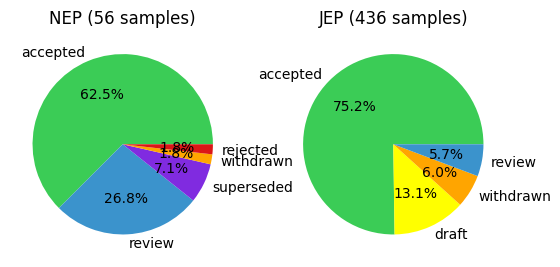

In [14]:
from collections import Counter

# status_stats = dict()
projects = list(session.scalars(select(Project)))

print('Current status proportions:')
for i, project in enumerate(projects):
  status_counts = Counter()
  for prop_id in session.scalars(select(Proposal.proposal_id).where(Proposal.project_id.is_(project.project_id))):
    latest_status = session.scalar(select(ProposalStatus.normalised_status)
      .where(ProposalStatus.project_id.is_(project.project_id))
      .where(ProposalStatus.proposal_id.is_(prop_id))
      .order_by(ProposalStatus.status_index.desc())
      .limit(1))
    status_counts[latest_status] += 1
  # status_stats[project.enhancement_proposal_name] = status_counts
  status_counts_ord = status_counts.most_common()

  plt.subplot(1, len(projects), i+1)
  plt.title(f'{project.enhancement_proposal_name} ({status_counts.total()} samples)')
  plt.pie([s[1] for s in status_counts_ord],
    labels=[s[0].value for s in status_counts_ord],
    colors=[status_color[s[0]] for s in status_counts_ord],
    autopct='%1.1f%%')

plt.show()

Picking the most popular proposals in each project, for me to manually read through and discover traits:

In [15]:
from sqlalchemy import func

num_to_take = 5

print('By number of comments:')
for project in projects:
  most_comments = session.scalars(select(Proposal.proposal_id)
    .join(Comment)
    .where(Proposal.project_id.is_(project.project_id))
    .group_by(Proposal.proposal_id)
    .order_by(func.count(Comment.comment_id).desc())
    .limit(num_to_take))
  print(f'{project.enhancement_proposal_name}: {list(most_comments)}')

print('By number of revisions:')
for project in projects:
  most_comments = session.scalars(select(Proposal.proposal_id)
    .join(ProposalRevision)
    .where(Proposal.project_id.is_(project.project_id))
    .group_by(Proposal.proposal_id)
    .order_by(func.count(ProposalRevision.revision_index).desc())
    .limit(num_to_take))
  print(f'{project.enhancement_proposal_name}: {list(most_comments)}')

By number of comments:
NEP: ['14', '18', '20', '17', '41']
JEP: ['331', '472', '450', '537', '223']
By number of revisions:
NEP: ['50', '35', '29', '18', '0']
JEP: ['537', '533', '506', '454', '532']
